In [ ]:
"""
Phase 3: NLP EDA on the 38K review column.
Goal: understand text quality issues before running a sentiment classifier on it -
text length, duplicates, vocabulary size, and missing/short reviews.

"""

In [1]:
%matplotlib inline

import re
import string
from collections import Counter
 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
# ---------------- CONFIG (edit to match your file) ----------------
MAIN_PATH = "../data/raw/38000_review.csv"
REVIEW_COL = "review"
ID_COL = "review_id"          # created below if it doesn't exist
SHORT_WORD_THRESHOLD = 3       # reviews with <= this many words are flagged "short"
# --------------------------------------------------------------------

In [3]:
df = pd.read_csv(MAIN_PATH)
 
if ID_COL not in df.columns:
    df[ID_COL] = df.index
 
print(f"Rows: {len(df)}")

Rows: 31938


In [4]:
# 1. Missing reviews
n_missing = df[REVIEW_COL].isna().sum()
print(f"Missing reviews: {n_missing} ({n_missing / len(df) * 100:.2f}%)")

Missing reviews: 0 (0.00%)


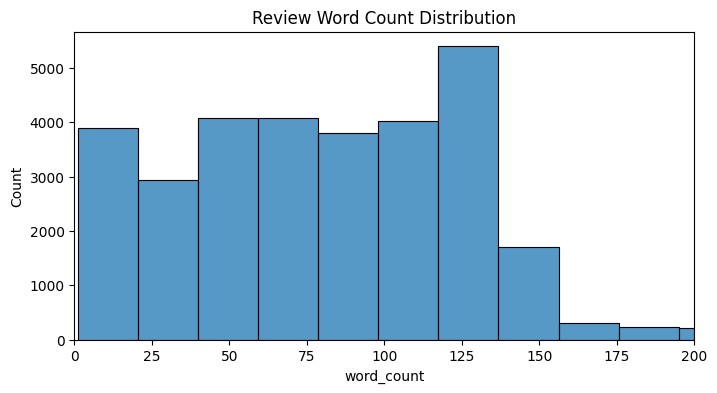

In [5]:
# 2. Text length distribution
df["word_count"] = df[REVIEW_COL].fillna("").apply(lambda x: len(str(x).split()))
df["char_count"] = df[REVIEW_COL].fillna("").apply(lambda x: len(str(x)))

plt.figure(figsize=(8, 4))
sns.histplot(df["word_count"], bins=50)
plt.xlim(0, 200)
plt.title("Review Word Count Distribution")
plt.show()

In [6]:
print(df["word_count"].describe())

count    31938.000000
mean        91.476298
std         79.444580
min          1.000000
25%         45.000000
50%         83.000000
75%        122.000000
max        971.000000
Name: word_count, dtype: float64


In [7]:
# 3. Short reviews
short_reviews = df[df["word_count"] <= SHORT_WORD_THRESHOLD]
print(f"\nShort reviews (<= {SHORT_WORD_THRESHOLD} words): {len(short_reviews)} "
      f"({len(short_reviews) / len(df) * 100:.2f}%)")


Short reviews (<= 3 words): 169 (0.53%)


In [10]:
# 4. Duplicates - exact, and normalized (lowercase, punctuation stripped)
exact_dupes = df[df.duplicated(subset=[REVIEW_COL], keep=False)]
print(f"Exact duplicate reviews: {len(exact_dupes)}")

Exact duplicate reviews: 122


In [11]:
def normalize(text):
    text = str(text).lower().strip()
    text = text.translate(str.maketrans("", "", string.punctuation))
    return re.sub(r"\s+", " ", text) 
 
df["review_normalized"] = df[REVIEW_COL].fillna("").apply(normalize)
normalized_dupes = df[df.duplicated(subset=["review_normalized"], keep=False)]
print(f"Normalized duplicate reviews (case/punctuation-insensitive): {len(normalized_dupes)}")

Normalized duplicate reviews (case/punctuation-insensitive): 160


In [12]:
# 5. Vocabulary check
def tokenize(text):
    return re.findall(r"\b[a-z]{2,}\b", str(text).lower())
 
 
all_words = []
for t in df[REVIEW_COL].dropna():
    all_words += tokenize(t)
 
vocab = Counter(all_words)
print(f"\nVocabulary size (unique words): {len(vocab)}")
print(f"\nTop 20 words:", vocab.most_common(20))
 
rare_words = [w for w, c in vocab.items() if c == 1]
print(f"\nRare words (appear once): {len(rare_words)} ({len(rare_words) / len(vocab) * 100:.1f}% of vocab)")


Vocabulary size (unique words): 29815

Top 20 words: [('the', 164514), ('and', 91249), ('it', 63284), ('is', 62903), ('to', 61450), ('car', 55781), ('in', 37165), ('this', 36659), ('of', 36530), ('for', 32258), ('with', 27702), ('my', 27641), ('have', 24444), ('on', 24432), ('but', 21773), ('that', 21261), ('you', 20105), ('not', 17911), ('was', 16199), ('great', 15827)]

Rare words (appear once): 13120 (44.0% of vocab)


In [13]:
# 6. Save flagged table for cleaning decisions in Phase 4
df["is_missing"] = df[REVIEW_COL].isna()
df["is_short"] = df["word_count"] <= SHORT_WORD_THRESHOLD
df["is_exact_duplicate"] = df.duplicated(subset=[REVIEW_COL], keep="first")
df["is_normalized_duplicate"] = df.duplicated(subset=["review_normalized"], keep="first")
 
df.drop(columns=["review_normalized"]).to_csv("../data/interim/phase3_38k_flagged.csv", index=False)
print("\nDone. Check phase3_word_count_dist.png and phase3_38k_flagged.csv")


Done. Check phase3_word_count_dist.png and phase3_38k_flagged.csv


In [19]:
import os

os.makedirs('data', exist_ok=True)
df = pd.read_csv("../data/interim/38000_processed.csv")


# Map requested schema to actual dataframe columns[cite: 2]
export_cols = ['review_id', 'brand_name', 'car_year', 'date', 'Rating', 
               REVIEW_COL, 'word_count', 'is_duplicate', 'is_short', 'is_missing']

rename_map = {
    'Rating': 'rating', 
    REVIEW_COL: 'review_text'
}

# Export without hard-deleting flagged rows
export_df = df[export_cols].rename(columns=rename_map)
export_df.to_csv('../data/processed/cleaned_reviews.csv', index=False)

KeyError: "['is_duplicate'] not in index"